# CNN RFI family weakness analysis
**CNN · 8 base channels · BCE · learning rate 0.0003**

This notebook uses saved **validation results**, covering 60 recordings.

In [ ]:
import os
import tempfile
os.environ.setdefault('MPLCONFIGDIR', os.path.join(tempfile.gettempdir(), 'rfi-matplotlib'))
import csv
import json
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

MODEL = 'model_matched_clean_fpr'
COUNTS = ('tp', 'fp', 'fn', 'tn')


def read_csv(path):
    with path.open(newline='') as f:
        return list(csv.DictReader(f))


def divide(a, b):
    return np.divide(a, b, out=np.full(np.broadcast(a, b).shape, np.nan), where=np.asarray(b) != 0)


def metrics(counts):
    tp, fp, fn, tn = np.asarray(counts).T
    return np.array([divide(tp, tp+fp), divide(tp, tp+fn),
                     divide(2*tp, 2*tp+fp+fn), divide(tp, tp+fp+fn),
                     divide(fp, fp+tn), divide(fn, tp+fn)]).T


def write_csv(path, rows):
    with path.open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


from IPython.display import display, Image, Markdown


In [ ]:
# Works when launched from Week3 or the project root. Edit RUN_DIR if needed.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'cnn_b8_grid').is_dir()), Path.cwd())
RUN_DIR = ROOT / 'cnn_b8_grid/bce_lr0.0003'
EVALUATION_DIR = RUN_DIR / 'evaluation_validation_20261020T053309Z_ffa6fd'
OUTPUT_DIR = ROOT / 'Week3/rfi_family_analysis'

The cells below load the saved per-antenna counts and per-family AP, then calculate precision, recall, and error rates. For uncertainty intervals, antennas from the same recording stay together during bootstrap resampling (2,000 replicates).

In [3]:
run = RUN_DIR
out = OUTPUT_DIR
metadata = json.loads((EVALUATION_DIR / 'run_metadata.json').read_text())
summary = json.loads((EVALUATION_DIR / 'summary.json').read_text())
calibration = summary['calibration']
source = read_csv(EVALUATION_DIR / 'per_antenna.csv')
ap = {r['rfi_type']: float(r['pixel_ap_quantized']) for r in
      read_csv(EVALUATION_DIR/'model_pixel_AP_by_family.csv') if r['pixel_ap_quantized']}
families = sorted(ap, key=ap.get)
all_families = families + sorted({r['rfi_type'] for r in source} - set(families))
methods = sorted({r['method'] for r in source})
rng = np.random.default_rng(163)
result = []
names = ['precision', 'recall', 'f1', 'iou', 'fpr', 'miss_rate']
for family in all_families:
    for method in methods:
        selected = [r for r in source if r['rfi_type'] == family and r['method'] == method]
        groups = {}
        for r in selected:
            groups.setdefault(r['sample_id'], np.zeros(4, dtype=np.int64))
            groups[r['sample_id']] += np.array([int(r[k]) for k in COUNTS])
        if not groups:
            raise ValueError(f'Missing {family}/{method}')
        counts = np.stack(list(groups.values()))
        total = counts.sum(axis=0)
        values = metrics(total)
        row = dict(rfi_type=family, method=method, recordings=len(groups), antennas=len(selected),
                   **dict(zip(COUNTS, total.tolist())), **dict(zip(names, values.tolist())))
        row['prevalence'] = float(divide(total[0]+total[2], total.sum()))
        row['pixel_ap_quantized'] = ap.get(family, float('nan')) if method == MODEL else float('nan')
        if method == MODEL:
            draws = rng.integers(0, len(counts), (2000, len(counts)))
            boot = metrics(counts[draws].sum(axis=1))
            for i, name in enumerate(names):
                finite = boot[:, i][np.isfinite(boot[:, i])]
                lo, hi = np.percentile(finite, [2.5, 97.5]) if len(finite) else (np.nan, np.nan)
                row[name+'_ci_low'], row[name+'_ci_high'] = float(lo), float(hi)
        result.append(row)
out.mkdir(parents=True, exist_ok=True)
# Give all CSV rows the same schema, including baseline rows without CIs.
fields = list(dict.fromkeys(k for r in result for k in r))
write_csv(out/'family_metrics.csv', [{k:r.get(k, '') for k in fields} for r in result])
model = {r['rfi_type']:r for r in result if r['method'] == MODEL}
plt.rcParams.update({'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})
def save(fig, name):
    fig.savefig(out/(name+'.png'), dpi=180, bbox_inches='tight')
    fig.savefig(out/(name+'.svg'), bbox_inches='tight')
    display(Image(filename=str(out/(name+'.png'))))
    plt.close(fig)


## Saved decision threshold
A positive prediction means **RFI**. The saved rule is `floor(sigmoid(logit) × 65535) >= 1786`, mathematically equivalent to a sigmoid score **at least 1786 / 65535 ≈ 0.0272526**. Evaluation preserves the quantized rule.

The cutoff was calibrated on three clean validation recordings to match the approximately 1.224% clean false-positive rate of `sk-bandpass`. The sigmoid scores are not necessarily calibrated probabilities; the cutoff is not a confidence guarantee.

In [4]:
print(f"Split: {metadata['evaluation_split']} | Selected epoch: {metadata['selected_epoch']}")
print(f"Overall pixel AP: {summary['pixel_ap_quantized']:.4f}")
print(f"Saved score threshold: {calibration['probability_lower_bound']:.7f}")

Split: validation | Selected epoch: 35
Overall pixel AP: 0.6409
Saved score threshold: 0.0272526


## 1. Validation dataset breakdown and baseline detection performance

Four panels show, for each family:

1. **Validation share:** fraction of all validation pixel locations belonging to that family.
2. **RFI prevalence:** fraction of that family's pixels labeled RFI.
3. **Pixel AP:** baseline CNN ranking performance across thresholds.
4. **Recall:** fraction of labeled RFI detected at the saved validation cutoff (~0.02725).

The absolute pixel-count panel has been removed. All panels use the same family order. AP and recall are undefined for clean and sky, which have no positive labels; these entries are marked N/A, not zero. AP and recall use a 0–1 score scale; the first two panels use percentages.

Counts use one method per recording/antenna, without multiplying by baseline methods. Families label recordings; mixed does not isolate individual emitters. These are validation results used for model selection and calibration, not an independent test.


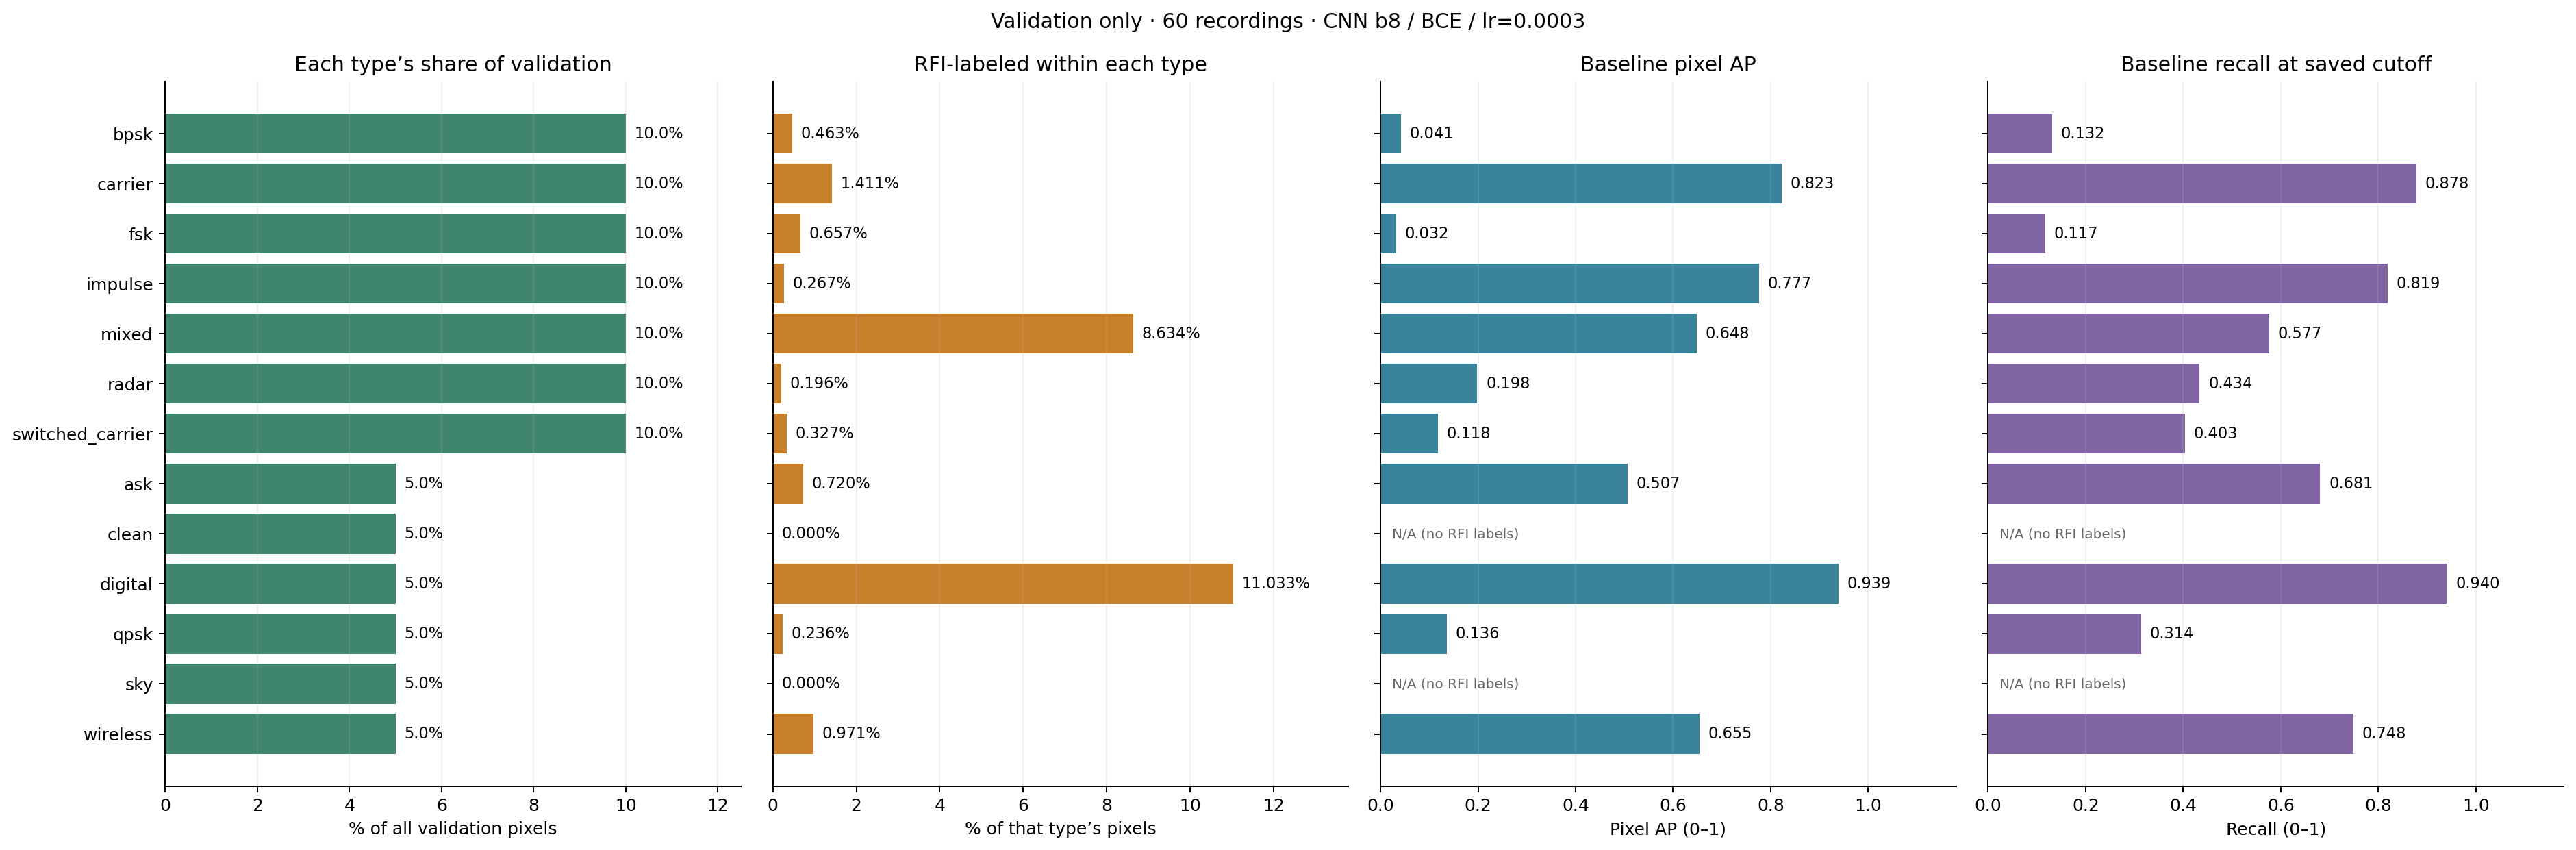

In [10]:
# One method supplies each sample/antenna exactly once; do not sum methods.
breakdown = []
total_pixels = sum(sum(model[f][k] for k in COUNTS) for f in all_families)
for f in sorted(all_families, key=lambda f: (-sum(model[f][k] for k in COUNTS), f)):
    r = model[f]
    pixels = sum(r[k] for k in COUNTS)
    breakdown.append(dict(rfi_type=f, recordings=r['recordings'],
                          pixel_locations=pixels, rfi_pixels=r['tp']+r['fn'],
                          rfi_fraction=(r['tp']+r['fn'])/pixels,
                          dataset_fraction=pixels/total_pixels,
                          pixel_ap_quantized=r['pixel_ap_quantized'], recall=r['recall']))
write_csv(out/'dataset_breakdown.csv', breakdown)
fig, axes = plt.subplots(1, 4, figsize=(21, 7), sharey=True)
for ax, field, factor, title, xlabel, color in zip(
        axes, ['dataset_fraction','rfi_fraction','pixel_ap_quantized','recall'], [100,100,1,1],
        ["Each type’s share of validation",'RFI-labeled within each type','Baseline pixel AP','Baseline recall at saved cutoff'],
        ['% of all validation pixels',"% of that type’s pixels",'Pixel AP (0–1)','Recall (0–1)'],
        ['#40856d','#c8802b','#39849b','#8164a4']):
    vals = np.array([r[field]*factor for r in breakdown], dtype=float)
    finite = vals[np.isfinite(vals)]
    upper = 1.18 if factor == 1 else max(float(finite.max())*1.25, .1)
    ax.barh(np.arange(len(breakdown)), vals, color=color)
    for i, value in enumerate(vals):
        if not np.isfinite(value):
            ax.text(.02*upper, i, 'N/A (no RFI labels)', va='center', fontsize=8, color='#666666')
        else:
            label = f'{value:.3f}' if factor == 1 else f'{value:.3f}%' if field == 'rfi_fraction' else f'{value:.1f}%'
            ax.text(value + upper*.015, i, label, va='center', fontsize=9)
    ax.set(title=title, xlabel=xlabel, xlim=(0,upper))
    ax.grid(axis='x', alpha=.2)
axes[0].set_yticks(np.arange(len(breakdown)), [r['rfi_type'] for r in breakdown])
axes[0].invert_yaxis()
fig.suptitle(f"Validation only · {sum(r['recordings'] for r in breakdown)} recordings · CNN b8 / BCE / lr=0.0003")
fig.tight_layout()
save(fig, 'dataset_breakdown')


In [6]:
header = '| Family | Recordings | Pixel locations | RFI pixels | RFI within family | Share of validation |\n|---|---:|---:|---:|---:|---:|'
rows = [f"| {r['rfi_type']} | {r['recordings']} | {r['pixel_locations']:,} | {r['rfi_pixels']:,} | {r['rfi_fraction']:.3%} | {r['dataset_fraction']:.1%} |" for r in breakdown]
display(Markdown(header + '\n' + '\n'.join(rows)))
print(f"Total: {total_pixels:,} pixels; RFI: {summary['positive_cells']:,} ({summary['positive_cells']/total_pixels:.3%})")

| Family | Recordings | Pixel locations | RFI pixels | RFI within family | Share of validation |
|---|---:|---:|---:|---:|---:|
| bpsk | 6 | 31,457,280 | 145,630 | 0.463% | 10.0% |
| carrier | 6 | 31,457,280 | 443,972 | 1.411% | 10.0% |
| fsk | 6 | 31,457,280 | 206,584 | 0.657% | 10.0% |
| impulse | 6 | 31,457,280 | 83,986 | 0.267% | 10.0% |
| mixed | 6 | 31,457,280 | 2,716,118 | 8.634% | 10.0% |
| radar | 6 | 31,457,280 | 61,785 | 0.196% | 10.0% |
| switched_carrier | 6 | 31,457,280 | 102,782 | 0.327% | 10.0% |
| ask | 3 | 15,728,640 | 113,195 | 0.720% | 5.0% |
| clean | 3 | 15,728,640 | 0 | 0.000% | 5.0% |
| digital | 3 | 15,728,640 | 1,735,368 | 11.033% | 5.0% |
| qpsk | 3 | 15,728,640 | 37,057 | 0.236% | 5.0% |
| sky | 3 | 15,728,640 | 0 | 0.000% | 5.0% |
| wireless | 3 | 15,728,640 | 152,743 | 0.971% | 5.0% |

Total: 314,572,800 pixels; RFI: 5,799,220 (1.844%)


## 2. Comparison with classical baselines

Each cell contains a rate from 0 to 1. Higher recall and precision are better; lower false-positive rate is better. Brighter color always means a larger number, so consult the direction in the panel title.

These are saved operating points. Only CNN and sk-bandpass match clean-validation FPR; family-specific FPRs are not matched. Bandpass outperforms CNN on FSK at these settings; CNN substantially improves radar and impulse recall compared with the combined baseline. Blank cells are undefined metrics (for example, precision when nothing is flagged).

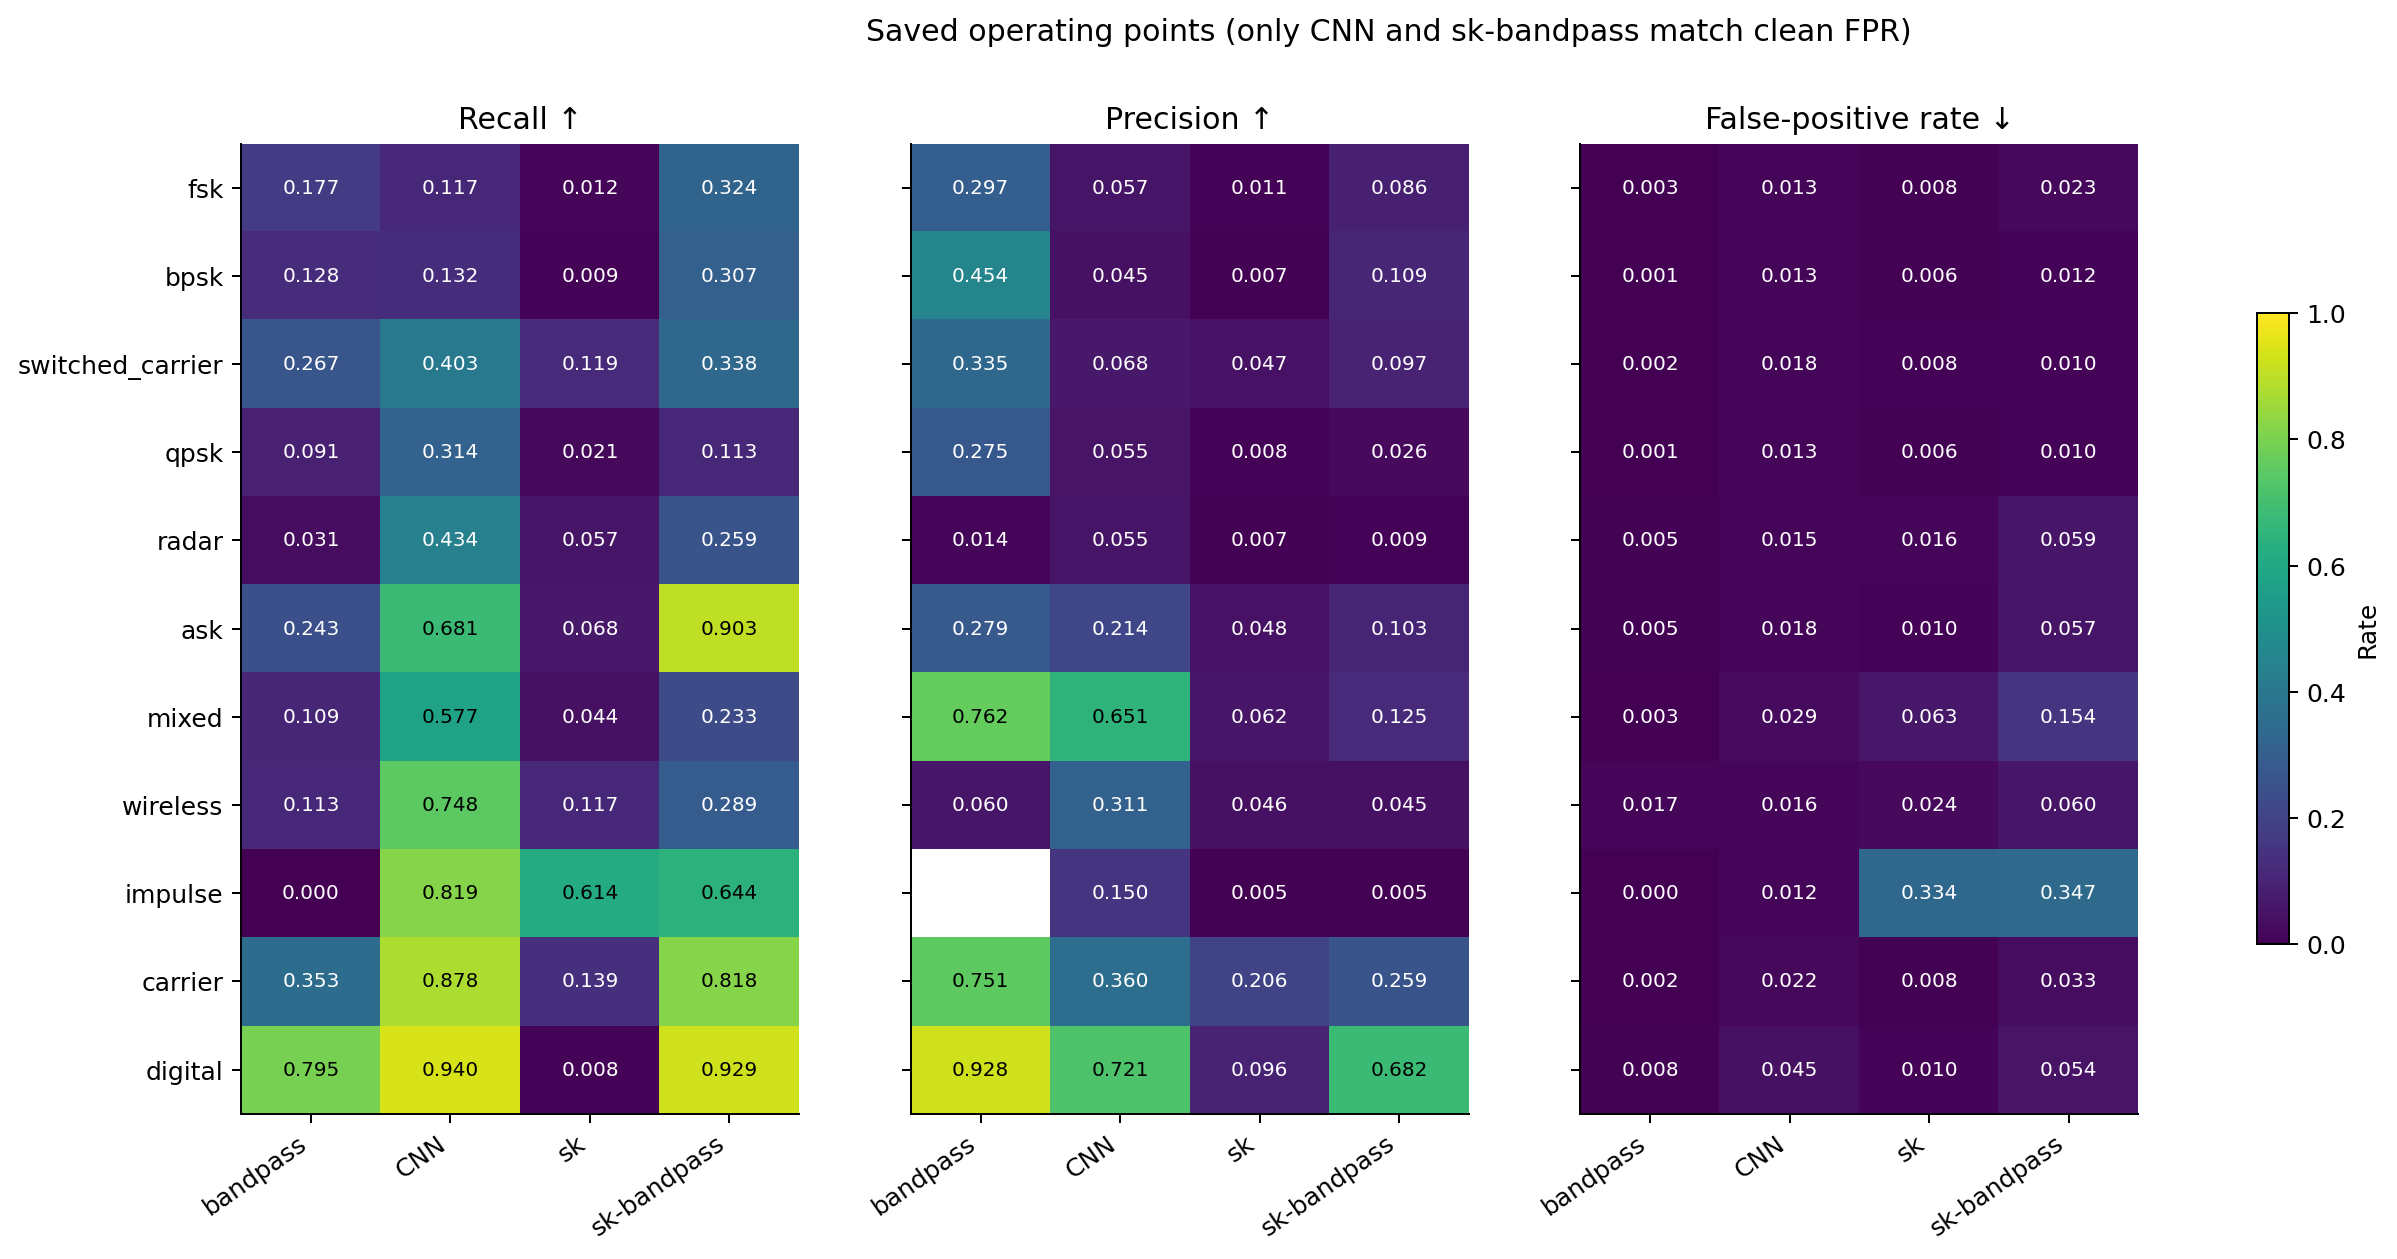

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 7), sharey=True)
for ax, metric, title in zip(axes, ['recall','precision','fpr'], ['Recall ↑','Precision ↑','False-positive rate ↓']):
    matrix = np.array([[next(r[metric] for r in result if r['rfi_type']==f and r['method']==m)
                        for m in methods] for f in families])
    image = ax.imshow(matrix, aspect='auto', vmin=0, vmax=1, cmap='viridis')
    for i in range(len(families)):
        for j in range(len(methods)):
            ax.text(j,i,f'{matrix[i,j]:.3f}',ha='center',va='center',fontsize=8,
                    color='black' if matrix[i,j]>.55 else 'white')
    ax.set_xticks(range(len(methods)), [m.replace(MODEL,'CNN') for m in methods],rotation=35,ha='right')
    ax.set_yticks(y, families)
    ax.set_title(title)
fig.colorbar(image, ax=axes.tolist(), shrink=.65, label='Rate')
fig.suptitle('Saved operating points (only CNN and sk-bandpass match clean FPR)')
save(fig, 'baseline_comparison')


## 4. Error proportions: compare families fairly

The two panels use explicitly different denominators:

- **False negative rate = FN/(TP+FN):** missed pixels as a percentage of actual RFI pixels.
- **False-positive rate = FP/(FP+TN):** false alarms as a percentage of actual non-RFI pixels.

Each is computed within a family, avoiding the dependence of absolute counts on family size. False negative rate is undefined for clean and sky, so they are omitted from that panel. Axes use percentages and different ranges to keep FPR differences visible. These are pooled pixel rates, not equally weighted averages of recording rates.

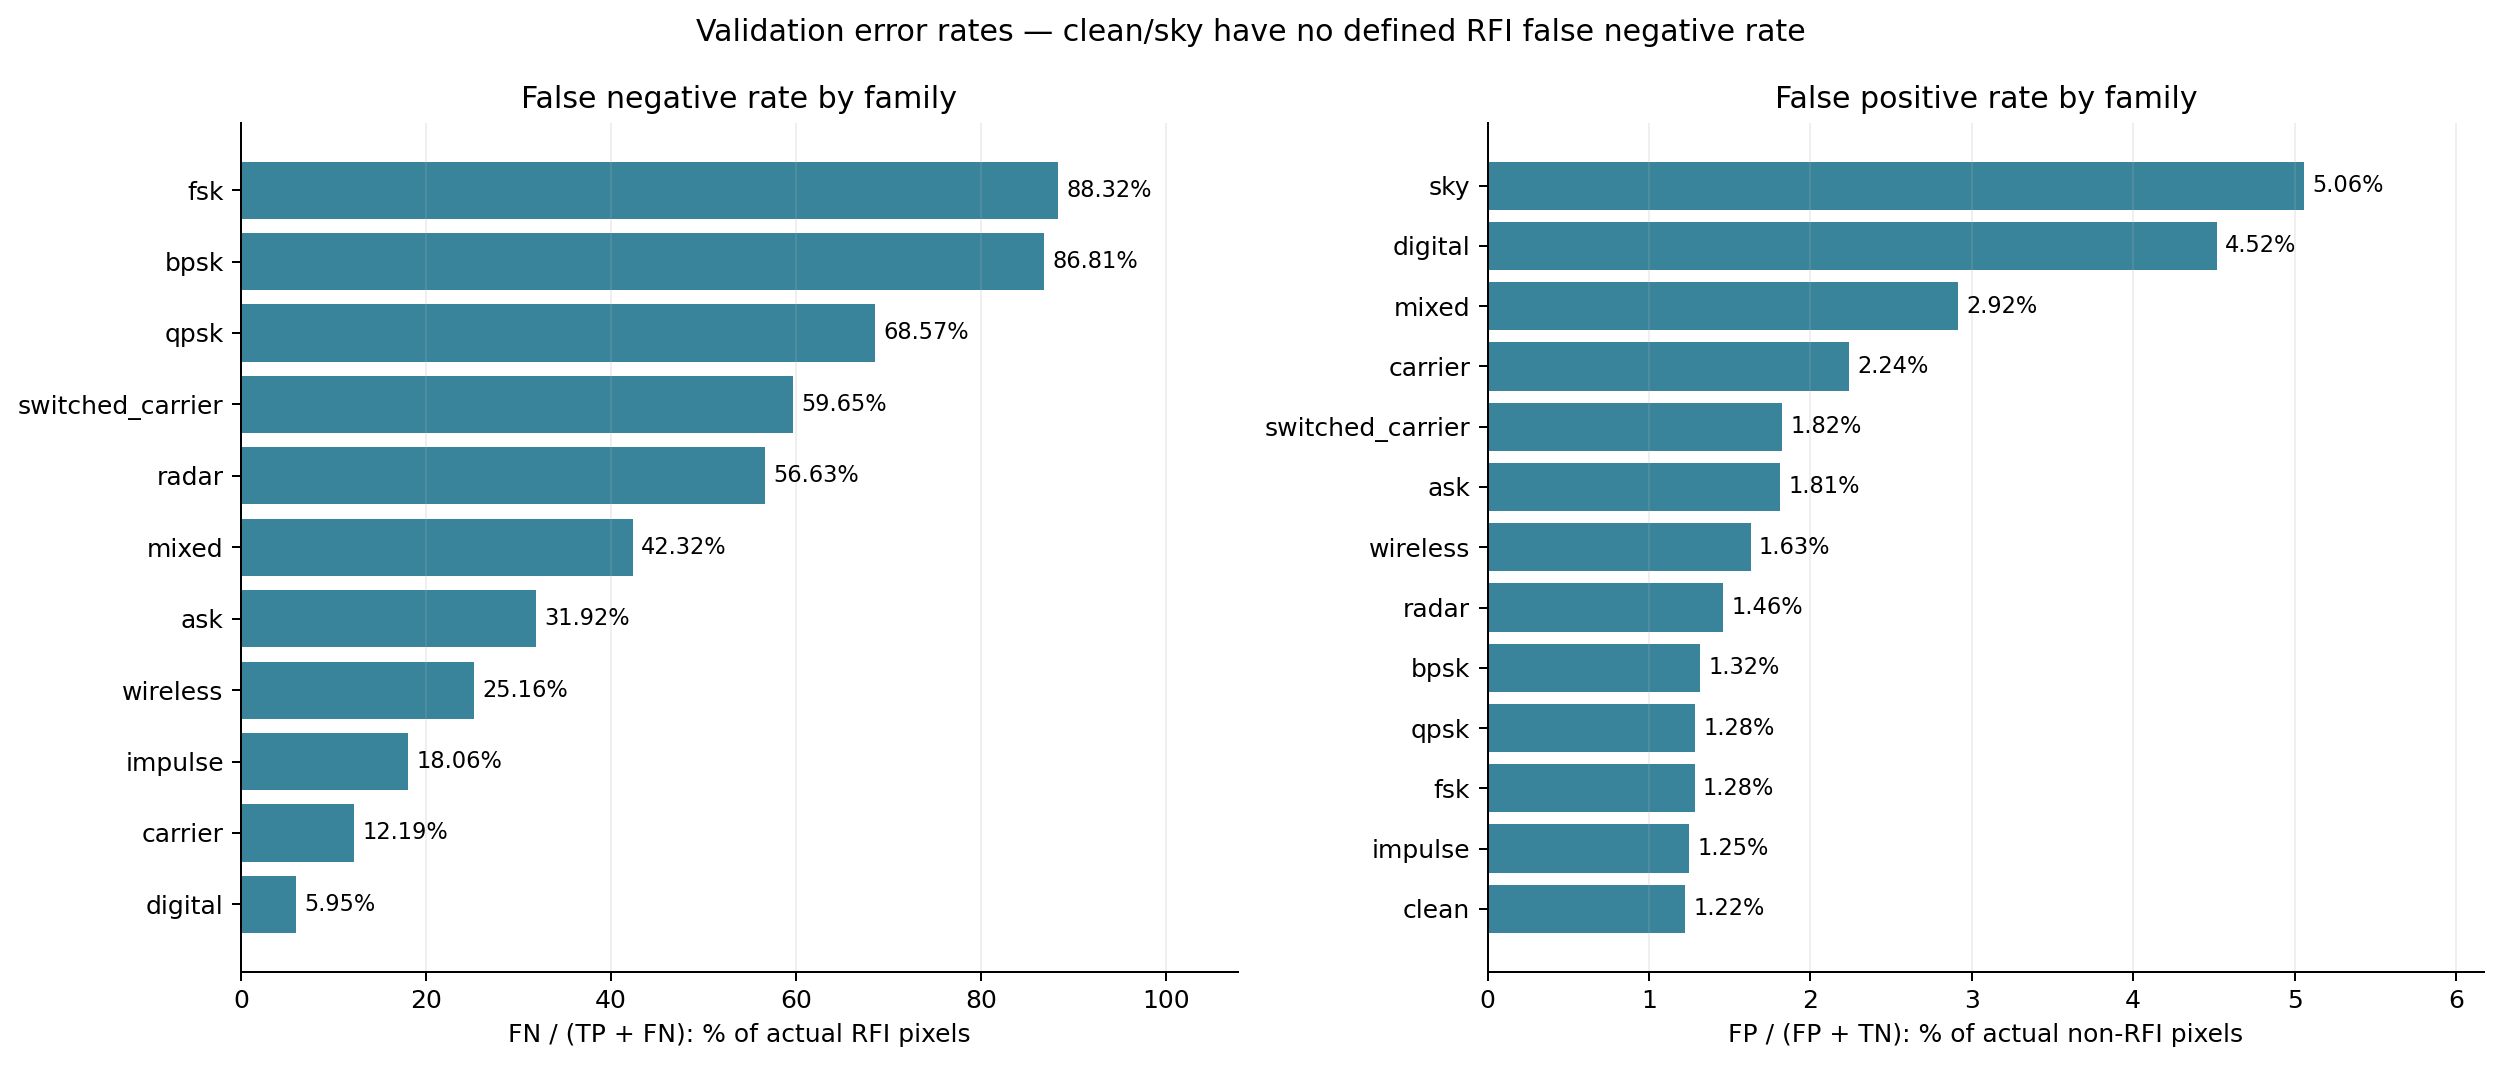

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, metric, title, denominator in zip(
        axes, ['miss_rate', 'fpr'],
        ['False negative rate by family', 'False positive rate by family'],
        ['FN / (TP + FN): % of actual RFI pixels',
         'FP / (FP + TN): % of actual non-RFI pixels']):
    order = sorted([f for f in all_families if np.isfinite(model[f][metric])],
                   key=lambda f: model[f][metric], reverse=True)
    vals = [100 * model[f][metric] for f in order]
    ax.barh(order, vals, color='#39849b')
    for i, value in enumerate(vals):
        ax.text(value + .01 * max(vals), i, f'{value:.2f}%', va='center', fontsize=9)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=denominator, xlim=(0, max(vals)*1.22))
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Validation error rates — clean/sky have no defined RFI false negative rate')
fig.tight_layout()
save(fig, 'error_proportions')



## Results and Limits of this Analysis

**The model struggles most with FSK and BPSK.** Out of every 100 pixels that actually contain FSK interference, it misses about 88. For BPSK, it misses about 87. It also misses about 69 out of 100 QPSK pixels, 60 out of 100 switched-carrier pixels, and 57 out of 100 radar pixels. These numbers use the saved detection threshold of approximately 0.02725.

**Changing the threshold might help, but it involves a tradeoff.** Lowering the threshold usually catches more interference, but also flags more pixels that do not contain interference. AP summarizes how well the model separates interference from background as this threshold changes. The low AP for FSK and BPSK suggests that finding a better threshold alone may not solve their problems. Impulse has much higher AP, but only about 15 out of every 100 pixels flagged at the current threshold are actual interference. Trying another threshold could be useful for impulse; we have not tested that change here.

**The model also flags some data that should be kept.** In the sky recordings, which have no labeled RFI, it incorrectly flags about 5 out of every 100 pixels. In the clean recordings, it flags about 1.2 out of every 100. This suggests a problem with preserving the sky examples. It does not tell us how much astronomical signal is lost, because different pixels can contain different amounts of signal.

**Some RFI types are much more common within their recordings than others.** For example, about 11% of pixels in the digital recordings contain RFI, compared with about 0.2% in the radar recordings. When interference is rare, even a small false-alarm rate can produce many wrong flags compared with correct detections. Use the dataset breakdown together with recall and false-positive rate when comparing families; precision and AP are affected by these differences.

**The baseline comparison uses each method's saved threshold.** The CNN and sk-bandpass were adjusted to incorrectly flag approximately the same fraction of clean-validation pixels. Other methods were not adjusted to match that rate. The plot shows how these saved settings compare; it does not prove which method would be best after trying different thresholds.

**We have only a small number of recordings.** Each family has 3 or 6 recordings. The black lines show how much the precision or recall estimate changes when we repeatedly resample those recordings. Antennas from one recording stay together because they observe the same event. Wider lines mean the estimate is less certain. These lines do not show how the result would change if we trained the model again. We do not have enough saved information to draw similar lines for AP.

**These are validation results, not a final test on new data.** The validation recordings were already used to choose the model checkpoint and detection threshold. We need a separate test set that was not used for those choices to measure how well the model performs on new recordings.

**The plots show where the model fails, but do not yet explain why.** A family name describes the recording; a mixed recording can contain several kinds of interference. To find the cause of a failure, we would need to inspect more examples and compare properties such as signal strength, duration, and frequency range.
